# Levitated optomechanics: from optical forces to linear quadratic Gaussian (LQG) stabilisation
### An illustrated, executable tutorial with one numerical example throughout

**Goal.** Understand (1) why light can trap a particle, (2) how the particle moves in a noisy optical potential, (3) the difference between cooling a stable trap and stabilising an unstable one, and (4) how a Kalman filter and a linear quadratic regulator (LQR) form an LQG controller.

**Approach.** We start from Newton's law, use one-dimensional models before extending to a two-dimensional double well, and generate figures from every important equation. No control-systems package is required: just NumPy, SciPy and Matplotlib.

**Source and scope.** Motivated by Mlynář *et al.* (and colleagues), *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems* (2026), especially §§2–4 and Fig. 5 (the supplied portable document format (PDF) article). The paper uses a field-programmable gate array (FPGA) controller and a second FPGA as a hardware-in-the-loop (HIL) simulator. **Our examples are illustrative software simulations, not reproductions of its measured traces or parameter settings.** We use classical mechanics and classical stochastic control; we do not claim quantum ground-state cooling.

**Learning path:** Run all cells in order. Figures are produced automatically. Experiment with the clearly marked parameters and exercises near the end.

## Abbreviations, notation and units

The main abbreviations are collected here so that you can refer back to them while reading. **Abbreviations** name techniques or hardware; **mathematical symbols** such as $A$, $B$, $Q$, $R$, $x$ and $\Omega$ are variables rather than abbreviations and are introduced where used.

| Abbreviation | Full form | Meaning in this tutorial |
|:--|:--|:--|
| **LQR** | **Linear Quadratic Regulator** | Optimal *state-feedback design*: selects gains to minimise a quadratic cost on motion and control effort. |
| **LQG** | **Linear Quadratic Gaussian** | The combination of an LQR controller and a Kalman state estimator for a linear system with Gaussian noise. |
| **FPGA** | **Field-Programmable Gate Array** | Reconfigurable digital hardware used to run the estimator and feedback law with predictable timing. |
| **HIL** | **Hardware-in-the-Loop** | Testing a real hardware controller against a real-time *simulated* physical plant. |
| **PD** | **Proportional–Derivative** | Feedback based on position error and its rate of change (velocity-like action). |
| **PID** | **Proportional–Integral–Derivative** | PD feedback with an additional integral term to correct persistent errors. |
| **MPC** | **Model Predictive Control** | Repeatedly solves a finite-horizon optimisation problem; can explicitly include actuator constraints. |
| **PDF** | **Portable Document Format** | File format of the cited research paper. |
| **1D / 2D / 3D** | **One / two / three dimensions** | Number of spatial directions in a model or optical trap. |

**A mathematical name, not an abbreviation:** $H_\infty$ is read *H-infinity*. In this context, it refers to a robust-control approach based on bounding the worst-case disturbance-to-output gain.

### Unit symbols appearing in text, plots and code

| Symbol | Unit | Used for |
|:--|:--|:--|
| **m, nm, $\mu$m** | metre, nanometre ($10^{-9}$ m), micrometre ($10^{-6}$ m) | Particle sizes, wavelength and beam waist. |
| **s, ns, $\mu$s** | second, nanosecond ($10^{-9}$ s), microsecond ($10^{-6}$ s) | Sampling periods and feedback delays. |
| **Hz, kHz, MHz** | hertz, kilohertz ($10^3$ Hz), megahertz ($10^6$ Hz) | Oscillation frequencies and FPGA sampling frequency. |
| **W, mW** | watt, milliwatt ($10^{-3}$ W) | Laser power. |
| **N, fN** | newton, femtonewton ($10^{-15}$ N) | Force. |
| **V** | volt | Detector and actuation signals in the physical experiment. |
| **F** | farad | Electric capacitance; appears in the polarizability unit $\mathrm{F\,m^2}$. |
| **kg** | kilogram | Particle mass. |
| **arb.** | arbitrary units | A plot shows a relative or normalised quantity rather than a calibrated physical magnitude. |

In citations, *et al.* is Latin shorthand for “and others”; **Fig.** means **Figure** and **§** means **section**. These are editorial conventions rather than control-system terminology.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are, solve_discrete_are, expm
from scipy.signal import cont2discrete
from scipy.stats import norm
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
rng = np.random.default_rng(12)
print('Ready: NumPy', np.__version__)

Ready: NumPy 2.4.6


## 1. How can light hold up a particle?

A laser exerts **two different forces** on a transparent dielectric particle:

- The **gradient force** pulls it towards regions of *higher light intensity* (for a particle with positive polarizability).
- The **scattering force** pushes it *along the direction in which the laser travels*.

A useful mental picture for a **large** transparent sphere is *refraction*: the sphere bends light rays, changing their momentum. Momentum conservation produces a reaction force on the sphere. If the sphere is off-centre in a beam, there is more light on the brighter side, so the sideways momentum transfers need not cancel. This explains the inward gradient force in the ray-optics regime.

For a **nanoparticle much smaller than the wavelength** (the Rayleigh regime), individual light rays are not a good approximation. Instead, the electric field of the laser induces a dipole:

$$
\mathbf p=\alpha\mathbf E,
$$

where $\alpha$ is its *polarizability*. For a small nonabsorbing sphere of radius $a$ in vacuum,

$$
\alpha=4\pi\epsilon_0a^3\frac{\epsilon_r-1}{\epsilon_r+2}.
$$

The electric field makes the positive and negative charges shift slightly in opposite directions. **A larger field induces a larger dipole and lowers the interaction energy more.** For real, positive $\alpha$, the time-averaged energy in a laser field with *peak* electric-field amplitude $E_0$ is

$$
U(\mathbf r)=-\frac14\alpha |E_0(\mathbf r)|^2
=-\frac{\alpha}{2\epsilon_0c}I(\mathbf r).
$$

The **minus sign** is the important part: bright regions have *lower potential energy*. Taking the spatial derivative gives the gradient force:

$$
\boxed{\mathbf F_{\mathrm{grad}}=-\nabla U
=\frac{\alpha}{2\epsilon_0c}\nabla I.}
$$

This force vanishes in a perfectly uniform beam and, transversely, at the exact centre of a symmetric beam. A particle displaced to either side is pulled back towards the intensity maximum.

### Why does the scattering force push forwards?

A photon carries momentum $p_\gamma=h/\lambda$. Even a **transparent** sphere redirects (scatters) photons. The incident beam loses some of its *forward* momentum, which must be transferred to the sphere. In the Rayleigh regime, the forward scattering force of a nonabsorbing sphere is approximately

$$
\boxed{F_{\mathrm{scat}}=\frac{I\,\sigma_{\mathrm{scat}}}{c}},\qquad
\sigma_{\mathrm{scat}}=\frac{k_0^4\alpha^2}{6\pi\epsilon_0^2},\quad
k_0=\frac{2\pi}{\lambda}.
$$

The two forces are **not opposite versions of the same force**: the gradient force follows the *spatial change* in intensity; the scattering force follows the *propagation direction*. At the transverse beam centre, the gradient force is zero while the scattering force is generally nonzero.

**Particle-size intuition:** in this approximation $\alpha\propto a^3$, so $F_{\mathrm{grad}}\propto a^3$, whereas $\sigma_{\mathrm{scat}}\propto a^6$, so $F_{\mathrm{scat}}\propto a^6$. Shrinking the particle reduces scattering more rapidly than the gradient force, with the illumination held fixed.

**A note on three-dimensional levitation:** a tightly focused laser also has an *axial* intensity gradient; that gradient can balance the forward scattering force (and gravity, depending on geometry). The resulting equilibrium may sit downstream of the focus. The one-dimensional transverse model below illustrates the restoring mechanism, but **does not by itself prove that a stable three-dimensional trap exists**.


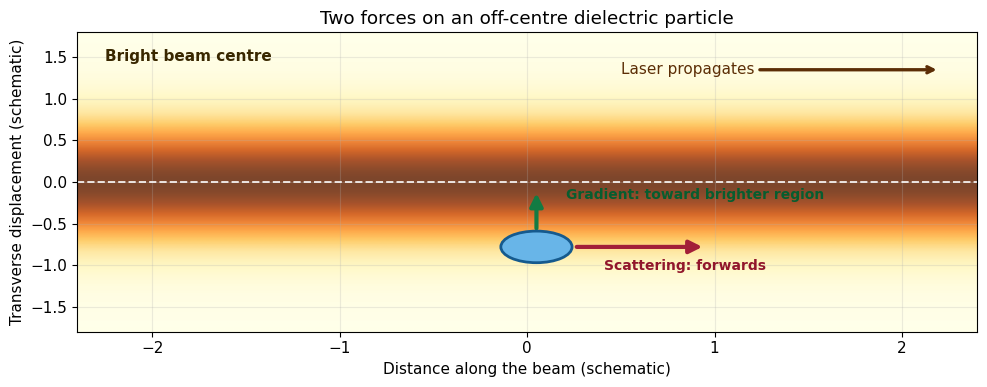

In [2]:
# Conceptual sketch: propagation is horizontal, transverse displacement vertical.
# (Arrows indicate force directions, not exact magnitudes.)
fig, ax = plt.subplots(figsize=(10, 4.0))
beam_z = np.linspace(-2.4, 2.4, 500)
beam_y = np.linspace(-1.8, 1.8, 340)
zz, yy = np.meshgrid(beam_z, beam_y)
intensity_map = np.exp(-2*yy**2) * np.ones_like(zz)
ax.imshow(intensity_map, extent=[-2.4, 2.4, -1.8, 1.8], origin='lower',
          cmap='YlOrBr', vmin=0, vmax=1, alpha=.85, aspect='auto')
ax.axhline(0, color='white', lw=1.4, ls='--', alpha=.85)
particle_z, particle_y = .05, -.78
ax.add_patch(plt.Circle((particle_z,particle_y),.19,fc='#68b5e8',ec='#155a8e',lw=2,zorder=5))
ax.annotate('',xy=(particle_z, particle_y+.68),xytext=(particle_z,particle_y+.19),
            arrowprops=dict(arrowstyle='-|>',color='#137b43',lw=3,mutation_scale=19))
ax.annotate('',xy=(particle_z+.9,particle_y),xytext=(particle_z+.2,particle_y),
            arrowprops=dict(arrowstyle='-|>',color='#a21f38',lw=3,mutation_scale=19))
ax.text(-2.25,1.45,'Bright beam centre',color='#392700',weight='bold',fontsize=11)
ax.text(.21,-.20,'Gradient: toward brighter region',color='#075d2f',weight='bold',fontsize=10)
ax.text(.41,-1.06,'Scattering: forwards',color='#91162b',weight='bold',fontsize=10)
ax.annotate('Laser propagates',xy=(2.2,1.35),xytext=(.5,1.35),
            arrowprops=dict(arrowstyle='->',lw=2.4,color='#5c2e06'),color='#5c2e06',va='center')
ax.set(xlim=(-2.4,2.4),ylim=(-1.8,1.8),xlabel='Distance along the beam (schematic)',
       ylabel='Transverse displacement (schematic)',title='Two forces on an off-centre dielectric particle')
fig.tight_layout(); plt.show()

### A numerical example with a silica nanoparticle

To see the different **directions and shapes** of the forces, consider a $100\,\mathrm{nm}$-diameter silica sphere ($n\approx1.45$) in a $1064\,\mathrm{nm}$ laser beam of power $10\,\mathrm{mW}$ and waist $w=0.8\,\mu\mathrm m$.

For a transverse displacement $y$ at the beam waist, assume the simple Gaussian profile

$$
I(y)=I_0 e^{-2y^2/w^2},\qquad I_0=\frac{2P}{\pi w^2}.
$$

Then

$$
F_{\mathrm{grad},y}=-\frac{2\alpha y}{\epsilon_0cw^2}I(y),\qquad
F_{\mathrm{scat},z}=\frac{\sigma_{\mathrm{scat}}}{c}I(y).
$$

Notice that $F_{\mathrm{grad},y}$ changes *sign* across the beam centre (a restoring force), but $F_{\mathrm{scat},z}$ always points forwards. The approximations assume a nonabsorbing Rayleigh particle and a local paraxial Gaussian beam; they do not calculate full three-dimensional trapping stability.

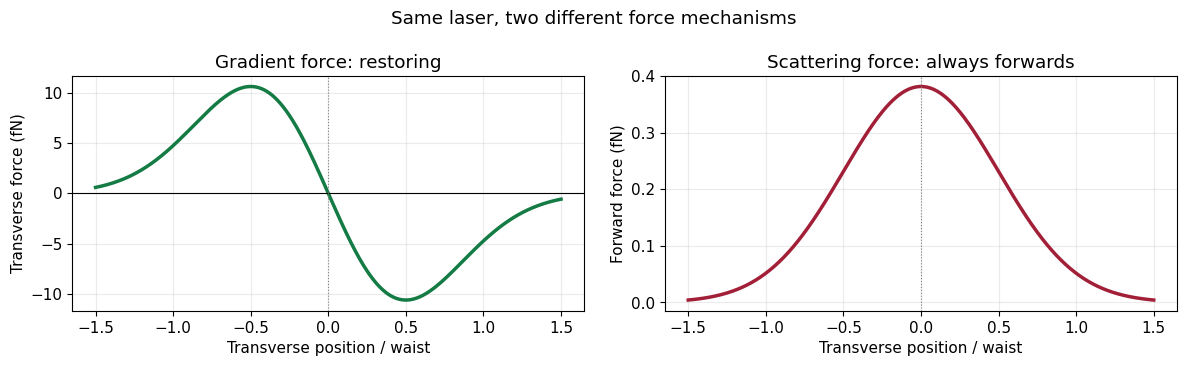

Polarizability: 3.74e-33 F m²
Scattering cross-section: 1.15e-17 m²
Gradient-force spring constant near centre: 4.38e-08 N/m
Approximate transverse trap frequency: 31.0 kHz
At the transverse centre: gradient force = 0; forward scattering force is maximal.


In [3]:
# Physical-parameter example (independent of the later dimensionless LQG simulations)
eps0 = 8.8541878128e-12          # vacuum permittivity [F/m]
c0 = 299792458.0                 # speed of light [m/s]
lam = 1064e-9                    # wavelength [m]
a = 50e-9                        # sphere radius [m]
n_silica = 1.45                  # refractive index relative to vacuum
P_laser = 10e-3                  # laser power [W]
w_beam = 0.8e-6                  # Gaussian waist [m]
alpha = 4*np.pi*eps0*a**3*(n_silica**2-1)/(n_silica**2+2)
k0 = 2*np.pi/lam
sigma_scat = k0**4*alpha**2/(6*np.pi*eps0**2)
I0 = 2*P_laser/(np.pi*w_beam**2)
y_m = np.linspace(-1.5*w_beam, 1.5*w_beam, 601)
Iy = I0*np.exp(-2*(y_m/w_beam)**2)
Fy = -(2*alpha*y_m/(eps0*c0*w_beam**2))*Iy
Fz = (sigma_scat/c0)*Iy

fig, axes = plt.subplots(1,2,figsize=(12,3.7))
axes[0].plot(y_m/w_beam, Fy*1e15,color='#137b43',lw=2.5)
axes[0].axhline(0,color='k',lw=.8)
axes[0].axvline(0,color='gray',lw=.8,ls=':')
axes[0].set(title='Gradient force: restoring',xlabel='Transverse position / waist',
            ylabel='Transverse force (fN)')
axes[1].plot(y_m/w_beam, Fz*1e15,color='#a21f38',lw=2.5)
axes[1].axvline(0,color='gray',lw=.8,ls=':')
axes[1].set(title='Scattering force: always forwards',xlabel='Transverse position / waist',
            ylabel='Forward force (fN)')
fig.suptitle('Same laser, two different force mechanisms')
fig.tight_layout(); plt.show()

U0 = alpha*I0/(2*eps0*c0)
k_spring = 4*U0/w_beam**2
rho_silica = 2200.0  # kg/m^3, representative silica density
mass = (4/3)*np.pi*a**3*rho_silica
f_trap = np.sqrt(k_spring/mass)/(2*np.pi)
print(f'Polarizability: {alpha:.2e} F m²')
print(f'Scattering cross-section: {sigma_scat:.2e} m²')
print(f'Gradient-force spring constant near centre: {k_spring:.2e} N/m')
print(f'Approximate transverse trap frequency: {f_trap/1e3:.1f} kHz')
print('At the transverse centre: gradient force = 0; forward scattering force is maximal.')

**Connection to the next section:** near the bright centre, the gradient force is almost linear in displacement, $F_y\simeq-ky$. That is exactly the **spring** in the harmonic-oscillator model used for the later Kalman filter and LQR. The scattering force primarily shifts the equilibrium along the direction of propagation; it is **not** the spring-like force in these transverse plots.

We now switch to **dimensionless units** to keep the rest of the LQG simulations simple.

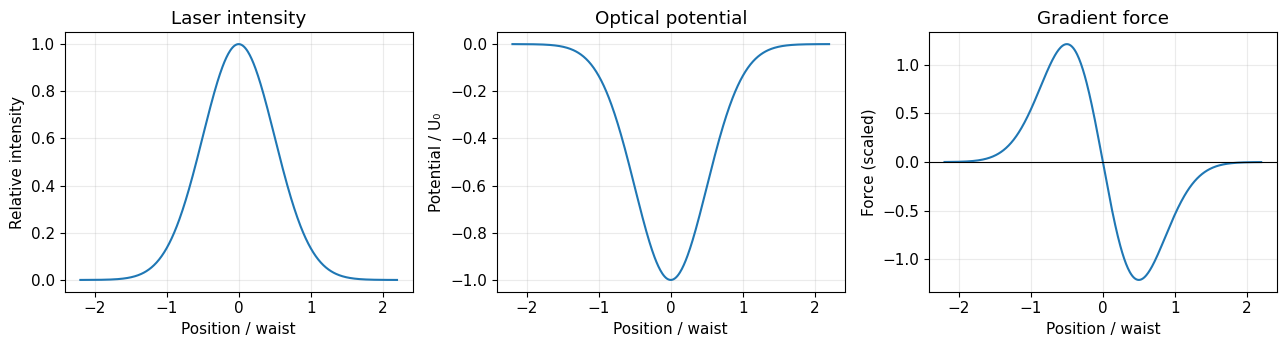

In [4]:
x = np.linspace(-2.2, 2.2, 500) # x / beam waist
I = np.exp(-2*x*x)
U = -I
F = -4*x*np.exp(-2*x*x) # -dU/dx
fig, ax = plt.subplots(1, 3, figsize=(13,3.6))
ax[0].plot(x,I); ax[0].set(title='Laser intensity',xlabel='Position / waist',ylabel='Relative intensity')
ax[1].plot(x,U); ax[1].set(title='Optical potential',xlabel='Position / waist',ylabel='Potential / U₀')
ax[2].plot(x,F); ax[2].axhline(0,color='k',lw=.8); ax[2].set(title='Gradient force',xlabel='Position / waist',ylabel='Force (scaled)')
fig.tight_layout();plt.show()

**Read the graphs:** the particle is attracted toward the intensity maximum at $x=0$. Close to that minimum, the force is approximately proportional to displacement: a spring! The above one-dimensional model is not by itself a proof of stable 3D levitation.

## 2. The optical trap is approximately a harmonic oscillator

Taylor-expand the potential near $x=0$:

$$
U(x)\simeq-U_0+\frac12kx^2,\quad k=\frac{4U_0}{w^2},\quad \Omega=\sqrt{k/m}.
$$

Newton's law, including gas damping, external feedback, and a fluctuating force, becomes

$$
m\ddot x+m\Gamma\dot x+m\Omega^2x=u(t)+F_{\rm noise}(t).
$$

The three important effects are **restoring stiffness** $m\Omega^2$, **damping** $m\Gamma$, and **random excitation**. The laser typically supplies the restoring force; feedback is optional for a stable trap.

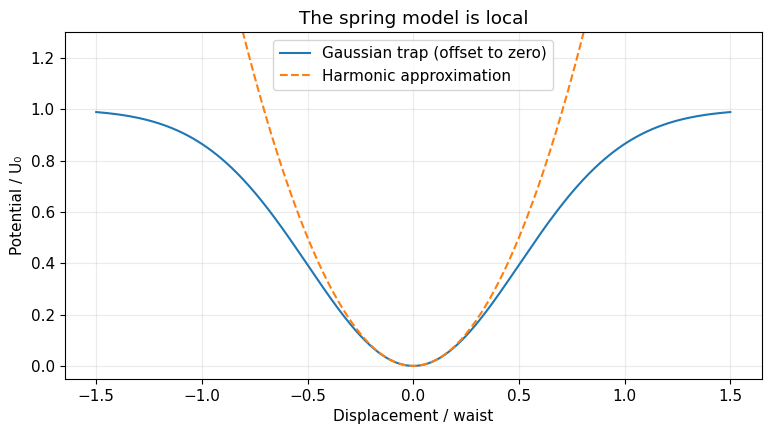

In [5]:
xx=np.linspace(-1.5,1.5,400)
exact=-np.exp(-2*xx**2)+1
quad=2*xx**2
plt.plot(xx,exact,label='Gaussian trap (offset to zero)')
plt.plot(xx,quad,'--',label='Harmonic approximation')
plt.ylim(-.05,1.3);plt.xlabel('Displacement / waist');plt.ylabel('Potential / U₀');plt.title('The spring model is local');plt.legend();plt.show()

## 3. Stable versus unstable equilibrium

A stable equilibrium sits at the **bottom** of a potential. A particle displaced slightly feels a restoring force. An unstable equilibrium sits at the **top**: a small displacement grows.

$$
\text{Stable: }\ddot x=-\Omega^2x-\Gamma\dot x,\qquad
\text{Unstable: }\ddot x=+\Omega^2x-\Gamma\dot x.
$$

In the paper's saddle-potential demonstration, one direction is locally unstable. This is the key reason feedback is **necessary for confinement**, not merely useful for cooling.

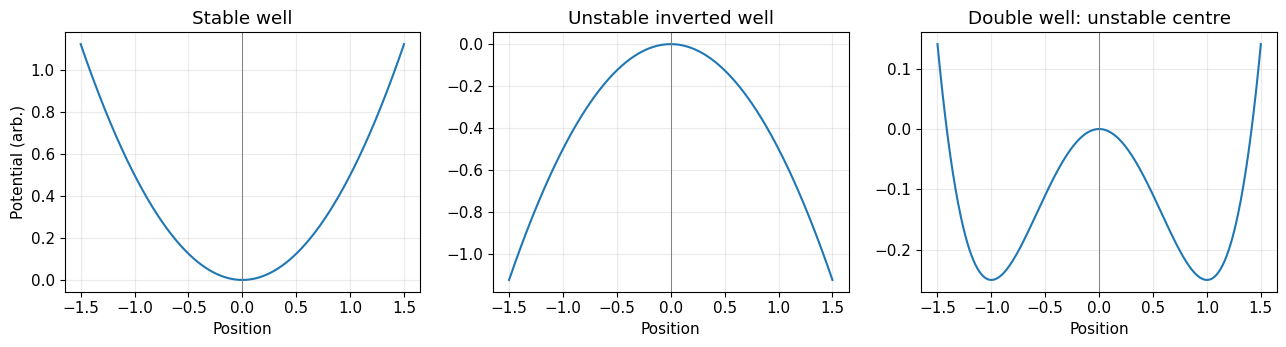

In [6]:
xx=np.linspace(-1.5,1.5,500)
fig,axs=plt.subplots(1,3,figsize=(13,3.6))
axs[0].plot(xx,.5*xx**2);axs[0].set(title='Stable well',ylabel='Potential (arb.)')
axs[1].plot(xx,-.5*xx**2);axs[1].set(title='Unstable inverted well')
axs[2].plot(xx,.25*xx**4-.5*xx**2);axs[2].set(title='Double well: unstable centre')
for a in axs:a.set(xlabel='Position');a.axvline(0,color='gray',lw=.7)
fig.tight_layout();plt.show()

## 4. One numerical particle, two kinds of trap

We now use **dimensionless units** so the plots are readable and the feedback equations are transparent. Time is measured in units of $1/\Omega_0$, and position in an arbitrary reference displacement. Let the characteristic angular frequency be $\Omega_0=1$ and damping $\Gamma=0.12$. This is *not* a fit to the paper's physical apparatus.

Let $s=+1$ denote stable stiffness and $s=-1$ inverted stiffness:

$$
\frac{d}{dt}\begin{bmatrix}x\\v\end{bmatrix}=
\underbrace{\begin{bmatrix}0&1\\-s\Omega_0^2&-\Gamma\end{bmatrix}}_A
\begin{bmatrix}x\\v\end{bmatrix}+
\underbrace{\begin{bmatrix}0\\1\end{bmatrix}}_B u.
$$

First, observe the unforced deterministic response from the same initial displacement.

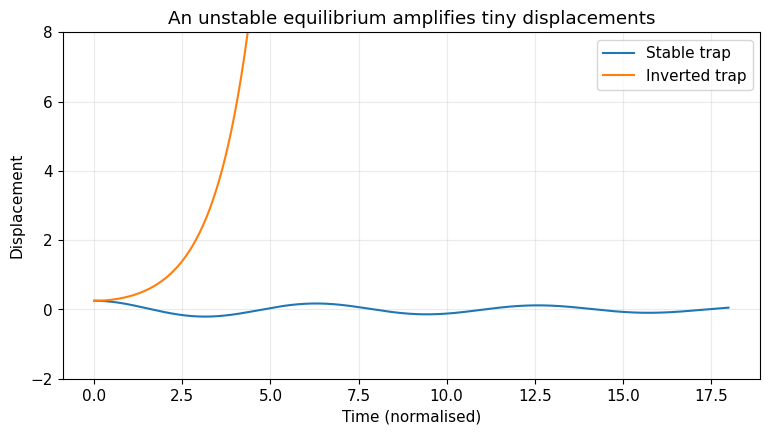

In [7]:
omega=1.0; gamma=.12
B=np.array([[0.],[1.]])
def plant(s):return np.array([[0.,1.],[-s*omega**2,-gamma]])
t=np.linspace(0,18,800);z0=np.array([.25,0.])
plt.plot(t,[ (expm(plant(1)*tt)@z0)[0] for tt in t],label='Stable trap')
plt.plot(t,[ (expm(plant(-1)*tt)@z0)[0] for tt in t],label='Inverted trap')
plt.ylim(-2,8);plt.xlabel('Time (normalised)');plt.ylabel('Displacement');plt.title('An unstable equilibrium amplifies tiny displacements');plt.legend();plt.show()

## 5. What does feedback actually change?

Suppose we can apply a force

$$
u=-k_xx-k_vv.
$$

For the inverted trap,

$$
\ddot x+(\Gamma+k_v)\dot x+(k_x-\Omega_0^2)x=0.
$$

Thus the controller must provide **positive effective stiffness** $k_x>\Omega_0^2$ (and positive total damping). In a stable trap, the main role of velocity feedback is often to increase damping, reducing motion caused by random disturbances. This is the difference between **stabilisation** and **cooling**.

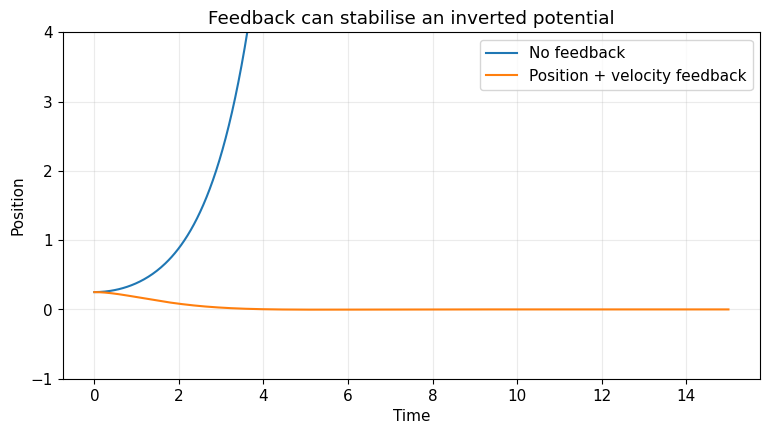

Open-loop poles: [ 0.942 -1.062]
Closed-loop poles: [-0.81+0.586j -0.81-0.586j]


In [8]:
from scipy.integrate import solve_ivp
K_example=np.array([2.0,1.5])
Aunstable=plant(-1)
Acl=Aunstable-B@K_example[None,:]
sol0=solve_ivp(lambda t,z:Aunstable@z,[0,15],z0,t_eval=np.linspace(0,15,600))
sol1=solve_ivp(lambda t,z:Acl@z,[0,15],z0,t_eval=np.linspace(0,15,600))
plt.plot(sol0.t,sol0.y[0],label='No feedback')
plt.plot(sol1.t,sol1.y[0],label='Position + velocity feedback')
plt.ylim(-1,4);plt.xlabel('Time');plt.ylabel('Position');plt.title('Feedback can stabilise an inverted potential');plt.legend();plt.show()
print('Open-loop poles:',np.linalg.eigvals(Aunstable).round(3))
print('Closed-loop poles:',np.linalg.eigvals(Acl).round(3))

## 6. From feedback to optimal control: linear quadratic regulation (LQR)

Rather than guessing $k_x$ and $k_v$, choose them to minimise

$$
J=\int_0^\infty(z^TQ_cz+ru^2)\,dt,\quad z=[x,v]^T.
$$

The matrix $Q_c$ penalises displacement and velocity; $r>0$ penalises control effort. For a *stable* harmonic trap, a physical energy-motivated choice is $Q_c\propto\operatorname{diag}(\Omega_0^2,1)$. For the *inverted* trap, this is a positive surrogate state penalty, **not** the physical potential energy (which has negative curvature).

The optimal gain is $K=r^{-1}B^TP$, where $P$ solves the continuous algebraic Riccati equation

$$
A^TP+PA-PBr^{-1}B^TP+Q_c=0.
$$

The paper implements a **discrete-time** LQR on the FPGA; here we first use continuous-time LQR to make the intuition clear.

In [9]:
Qcontrol=np.diag([2.,1.]);rcontrol=np.array([[.5]])
def lqr(A,Q=Qcontrol,R=rcontrol):
    P=solve_continuous_are(A,B,Q,R)
    return np.linalg.solve(R,B.T@P)
for s in [1,-1]:
    K=lqr(plant(s))
    print(('Stable' if s==1 else 'Inverted'), 'LQR gain [kx, kv] =',np.round(K.ravel(),3),
          'closed-loop poles =',np.round(np.linalg.eigvals(plant(s)-B@K),3))

Stable LQR gain [kx, kv] = [1.236 1.998] closed-loop poles = [-1.059+1.056j -1.059-1.056j]
Inverted LQR gain [kx, kv] = [3.236 2.793] closed-loop poles = [-1.457+0.338j -1.457-0.338j]


## 7. Why do we need a Kalman filter?

A photodetector provides a noisy signal related to **position**. It generally does not measure velocity directly. Differentiating noisy position samples makes the noise much worse.

A Kalman filter combines a dynamical model with incoming measurements to estimate both position and velocity:

$$
z_{k+1}=A_dz_k+B_du_k+w_k,\qquad y_k=Cz_k+v_k,\quad C=[1\;0].
$$

Here $w_k$ and $v_k$ are independent zero-mean Gaussian process and measurement noise with covariances $Q_d$ and $R_d$. The Kalman filter alternates **prediction** and **measurement correction**. We use an exact zero-order-hold discretisation for the deterministic model and the exact integrated covariance for continuous white acceleration noise.

In [10]:
dt=.04
A=plant(-1)
Ad,Bd,_,_,_=cont2discrete((A,B,np.array([[1.,0.]]),np.array([[0.]])),dt)
C=np.array([[1.,0.]])
# Exact covariance for white acceleration forcing with spectral density qacc
qacc=.12
Qc=qacc*(B@B.T)
M=np.block([[A,Qc],[np.zeros((2,2)),-A.T]])*dt
E=expm(M)
Qd=E[:2,2:]@E[:2,:2].T
Qd=(Qd+Qd.T)/2
Rmeas=.04**2
print('Discrete A:',Ad.round(4),' | Discrete process covariance:',Qd.round(7))

Discrete A: [[1.0008 0.0399]
 [0.0399 0.996 ]]  | Discrete process covariance: [[2.6000e-06 9.5600e-05]
 [9.5600e-05 4.7796e-03]]


### A single, reproducible stochastic experiment

To keep comparisons fair, the open-loop, full-state LQR, and LQG controllers experience the **same sequence of random force disturbances**. The measurement noise is also fixed in advance. The unstable open-loop trajectory will rapidly escape; in a real double well, nonlinear forces would eventually matter, so do not interpret the linear open-loop trajectory at very large displacements as physically realistic.

The filter uses the standard *predict → correct* recursion, with covariance updates in Joseph form for numerical robustness. Control is applied after the current measurement has been processed.

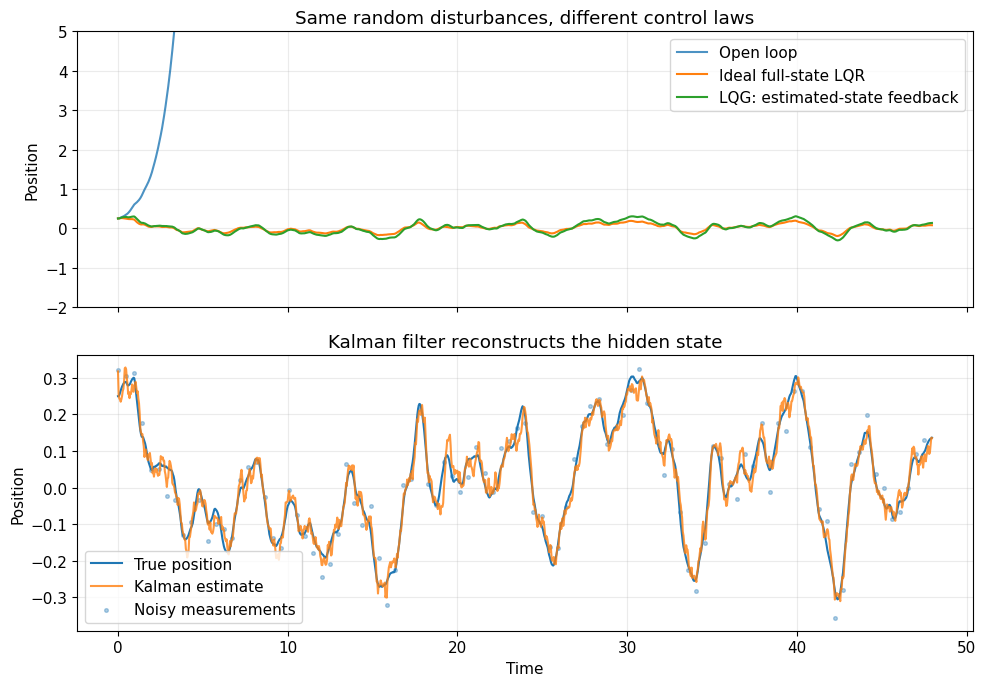

In [11]:
N=1200
rng=np.random.default_rng(2026)
W=rng.multivariate_normal([0,0],Qd,size=N)
V=rng.normal(0,np.sqrt(Rmeas),size=N)
K=lqr(A)
def simulate(mode):
    z=np.array([.25,0.]);zh=np.zeros(2);P=np.eye(2)*.2
    states=[];est=[];us=[];measure=[]
    for k in range(N):
        y=(C@z)[0]+V[k]
        # Measurement update
        innovation=y-(C@zh)[0]
        S=(C@P@C.T)[0,0]+Rmeas
        L=(P@C.T/S).ravel()
        zh=zh+L*innovation
        T=np.eye(2)-np.outer(L,C.ravel())
        P=T@P@T.T+np.outer(L,L)*Rmeas
        u=0. if mode=='open' else float(-(K@(z if mode=='full' else zh))[0])
        states.append(z.copy());est.append(zh.copy());us.append(u);measure.append(y)
        z=Ad@z+Bd.ravel()*u+W[k]
        zh=Ad@zh+Bd.ravel()*u
        P=Ad@P@Ad.T+Qd
    return np.array(states),np.array(est),np.array(us),np.array(measure)
open_state,_,_,_=simulate('open')
full_state,_,full_u,_=simulate('full')
lqg_state,lqg_est,lqg_u,lqg_y=simulate('lqg')
time=np.arange(N)*dt
fig,axs=plt.subplots(2,1,figsize=(10,7),sharex=True)
axs[0].plot(time,open_state[:,0],label='Open loop',alpha=.8)
axs[0].plot(time,full_state[:,0],label='Ideal full-state LQR')
axs[0].plot(time,lqg_state[:,0],label='LQG: estimated-state feedback')
axs[0].set(ylim=(-2,5),ylabel='Position',title='Same random disturbances, different control laws');axs[0].legend()
axs[1].plot(time,lqg_state[:,0],label='True position')
axs[1].plot(time,lqg_est[:,0],label='Kalman estimate',alpha=.8)
axs[1].scatter(time[::12],lqg_y[::12],s=7,alpha=.35,label='Noisy measurements')
axs[1].set(xlabel='Time',ylabel='Position',title='Kalman filter reconstructs the hidden state');axs[1].legend()
fig.tight_layout();plt.show()

## 8. Linear quadratic Gaussian (LQG) = LQR + Kalman filter

The **separation principle** says that, under the standard linear-Gaussian assumptions, the estimator and optimal feedback gains can be designed separately:

$$
\boxed{u_k=-K_d\hat z_{k|k}}.
$$

Our simulation above uses a continuous-time LQR gain applied to a sampled plant (adequate here at small $dt$). For the paper's FPGA, a **discrete-time LQR gain** is calculated directly. The following cell computes that exact discrete-time gain and compares it with our approximation.

In [12]:
Pd=solve_discrete_are(Ad,Bd,Qcontrol*dt,rcontrol*dt)
Kd=np.linalg.solve(Bd.T@Pd@Bd+rcontrol*dt,Bd.T@Pd@Ad)
print('Continuous-time LQR gain:',K.round(4))
print('Discrete-time LQR gain:  ',Kd.round(4))
print('Discrete closed-loop eigenvalues:',np.linalg.eigvals(Ad-Bd@Kd).round(4))

Continuous-time LQR gain: [[3.2361 2.7932]]
Discrete-time LQR gain:   [[3.1146 2.6977]]
Discrete closed-loop eigenvalues: [0.9433+0.0128j 0.9433-0.0128j]


### Why did the authors choose LQG rather than another controller?

The short answer is that **LQG is a natural engineering choice for a noisy, approximately linear mechanical system whose full state cannot be measured**. However, LQG is **not the only way to stabilise an inverted trap**, and the paper does not claim a controlled comparison proving it is superior to alternatives.

Recall that **LQG = Kalman state estimator + LQR state-feedback law**. These solve two *different* problems:

1. **Estimate what we cannot measure reliably.** The detector mostly provides noisy displacement-related voltages, not direct measurements of all velocities. A Kalman filter combines detector information with the oscillator model to estimate position and velocity. Simply differentiating a noisy position measurement tends to magnify high-frequency noise. (A filtered derivative or another observer can also work.)
2. **Choose how strongly to react.** The LQR chooses feedback gains to minimise a *specified* quadratic cost, typically penalising displacement, velocity and excessive force. In a **stable** harmonic trap, positive state weights can be chosen proportional to mechanical energy. At the **inverted** equilibrium, physical potential energy has negative curvature, so the positive LQR position penalty is an *energy-inspired stabilisation objective*, not the true local mechanical energy.
3. **Make noise explicit.** The Kalman estimator uses process- and measurement-noise covariances. It is minimum-mean-square-error optimal for the *assumed linear Gaussian model*, not automatically for an inaccurate or nonlinear one.
4. **Run fast on an FPGA.** Estimator and feedback gains can be calculated before the experiment. The real-time loop consists mostly of fixed-size matrix-vector operations. In the paper the controller updates every **64 ns** (15.625 MHz), using fixed-point arithmetic.

In a single-axis inverted trap, ordinary position-and-velocity feedback already has the form

$$
u=-k_x x-k_v v.$$

Its stability conditions in our normalised model are $k_x>\Omega_0^2$ and $\Gamma+k_v>0$. **Those conditions do not require LQG.** LQR is one systematic method for choosing the two gains; the Kalman filter supplies estimated states when the true states are not directly available.

| Method | Why we might use it | What it does not automatically solve |
|:--|:--|:--|
| **Proportional–derivative (PD) / proportional–integral–derivative (PID)** | Simple, cheap, often sufficient for one well-measured axis | Derivative noise; tuning multiple coupled modes |
| **Pole placement + observer** | Direct control over local closed-loop poles; efficient FPGA implementation | The poles alone do not select the best noise/effort trade-off |
| **LQG (Kalman + LQR)** | Explicit measurement/process noise model and quadratic performance criterion; precomputed gains | Does not guarantee robustness to plant uncertainty, delay or actuator saturation |
| **$H_\infty$ (H-infinity) control** | Can explicitly design for bounded disturbances/model uncertainty | Requires more involved modelling and weighting choices |
| **Model predictive control (MPC)** | Can incorporate input limits and state constraints directly | Typically needs more online computation; careful fast implementation |
| **Nonlinear control** | Can use the full double-well dynamics beyond a local linearisation | Generally more complex to design and validate |

**Important distinction:** The LQG law is still *linear observer-based state feedback*. Its special property is the **choice of gains** (and the assumptions that justify those choices), not a new physical mechanism of trapping.


LQR gains:                       [3.23607 2.79317]
Pole-placement gains, same poles: [3.23607 2.79317]
Pole-placement gains, other poles: [1.85 1.08]
Maximum same-pole gain difference: 4.440892098500626e-16


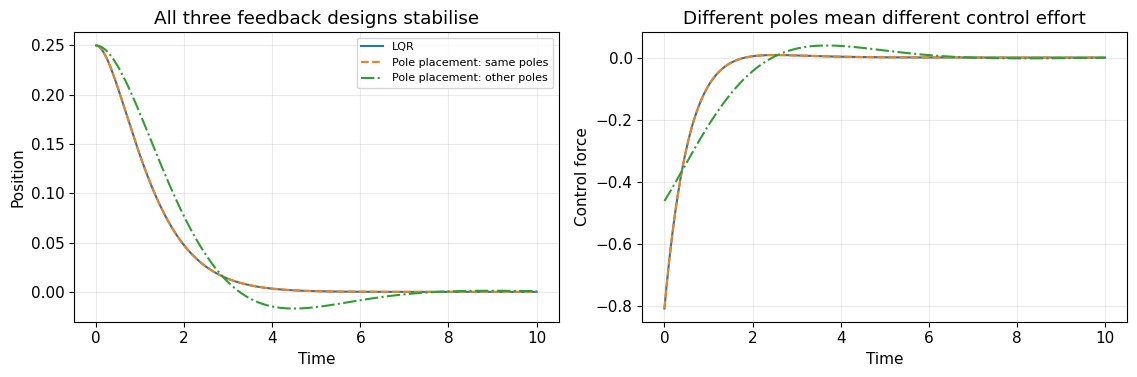

In [13]:
# Compare ordinary pole-placement feedback with the LQR from Sections 6-8.
# This is a deterministic illustration; it does NOT demonstrate that one
# controller is more robust or has lower noise-induced variance in practice.
from scipy.signal import place_poles

K_lqr_compare = lqr(plant(-1)).ravel()
A_compare = plant(-1)

# Choose the EXACT closed-loop poles obtained from LQR.
poles_lqr = np.linalg.eigvals(A_compare - B @ K_lqr_compare[None, :])
K_place_same = place_poles(A_compare, B, poles_lqr).gain_matrix.ravel()

# Choose some different but still stable poles for another valid PD controller.
other_poles = np.array([-0.6+0.7j, -0.6-0.7j])
K_place_other = place_poles(A_compare, B, other_poles).gain_matrix.ravel()

print('LQR gains:                      ', np.round(K_lqr_compare, 5))
print('Pole-placement gains, same poles:', np.round(K_place_same, 5))
print('Pole-placement gains, other poles:', np.round(K_place_other, 5))
print('Maximum same-pole gain difference:', np.max(abs(K_lqr_compare-K_place_same)))

# For a controllable two-state, one-input system, choosing the same poles
# uniquely fixes the state-feedback gain: it reproduces LQR exactly.
t_compare = np.linspace(0, 10, 500)
z_initial = np.array([0.25, 0.])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for gains, label, style in [
    (K_lqr_compare, 'LQR', '-'),
    (K_place_same, 'Pole placement: same poles', '--'),
    (K_place_other, 'Pole placement: other poles', '-.')
]:
    A_feedback = A_compare - B @ gains[None, :]
    trajectory = np.array([expm(A_feedback*t) @ z_initial for t in t_compare])
    applied_force = -(trajectory @ gains)
    axes[0].plot(t_compare, trajectory[:, 0], style, label=label)
    axes[1].plot(t_compare, applied_force, style, label=label)
axes[0].set(title='All three feedback designs stabilise', xlabel='Time', ylabel='Position')
axes[1].set(title='Different poles mean different control effort', xlabel='Time', ylabel='Control force')
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


**What does the comparison show?** In this *controllable, two-state, single-input* example, specifying exactly the LQR closed-loop poles via pole placement reproduces the LQR gains (and hence the same response). A different choice of stable poles also works, but gives different settling behaviour and feedback effort. This shows why **stabilisation alone does not establish that LQG is better than PD or pole placement**. For multiple-input systems, the same poles need not uniquely determine the feedback matrix.

### How strong is the evidence in the supplied paper?

Mlynář *et al.* demonstrate an FPGA implementation of the discrete-time Kalman filter and LQR, together with a **second FPGA acting as a nonlinear stochastic hardware-in-the-loop (HIL) particle simulator**. Their Section 4 and Figure 5 demonstrate reduced fluctuations in a confining potential, successful closed-loop confinement at an otherwise unstable saddle, and loss of central confinement when feedback is disabled. This is a convincing **implementation and stabilisation demonstration**. It does **not** establish:

- that LQG outperforms a comparably implemented PID, observer-based pole-placement, robust controller or MPC;
- that the same gain choice remains optimal far from the linearised equilibrium, especially when force saturates;
- that the experiment achieves quantum ground-state cooling (the reported end-to-end demonstration uses a HIL plant, not an actual trapped nanoparticle).

A useful *fair* comparison would keep the **same detector signals, Kalman estimator, actuator limits, sampling rate and disturbances**, replacing only the feedback gain selection (for example, LQR versus pole placement). Report position variance, control effort, settling time, sensitivity to uncertain trap stiffness or delay, and the **largest initial displacement that can be recovered**. The last metric is especially important for the double-well example in Section 10.

**Takeaway:** In this paper, LQG is attractive because it is **noise-aware, systematically designed and FPGA-friendly**. The unusual physics result is *stabilising an unstable trap*; LQG is a practical way to do so, not the only possible way.


## 9. Cooling and stabilisation are different control objectives

**Stable trap:** feedback can increase damping and reduce stationary motion in the presence of random forces. **Inverted trap:** without feedback, there is no stationary distribution about the central equilibrium; the first priority is to make the closed-loop dynamics stable.

For a stable linear system with white process noise, the steady-state state covariance $\Sigma$ satisfies the discrete Lyapunov equation

$$
\Sigma=A_{\rm cl}\Sigma A_{\rm cl}^T+Q_d.
$$

The mechanical energy in a *stable* harmonic trap (with $m=1$) is $E=(v^2+\Omega^2x^2)/2$. A smaller stationary variance corresponds to less mechanical energy. Here we simulate both open-loop and full-state velocity-feedback cooling; measurement-based LQG can add noise through its imperfect estimates.

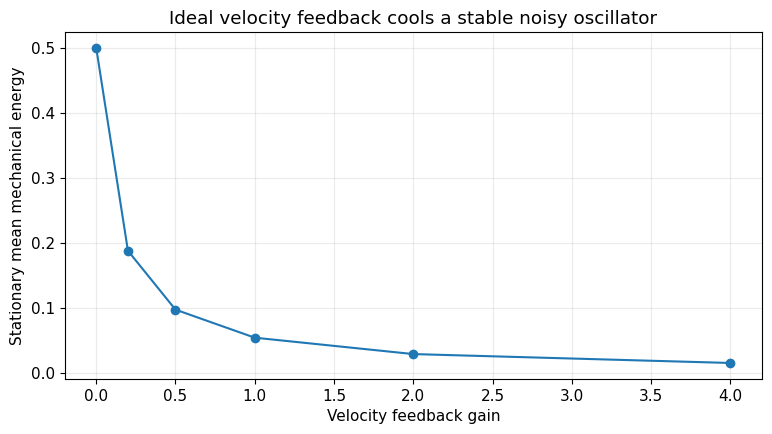

Energy without feedback: 0.5   with gain 2: 0.0289


In [14]:
from scipy.linalg import solve_discrete_lyapunov
Ast=plant(1)
Ads,Bds,_,_,_=cont2discrete((Ast,B,C,np.zeros((1,1))),dt)
M=np.block([[Ast,Qc],[np.zeros((2,2)),-Ast.T]])*dt
EM=expm(M);Qds=EM[:2,2:]@EM[:2,:2].T;Qds=(Qds+Qds.T)/2
energy=[]
for kv in [0,.2,.5,1.,2.,4.]:
    F=Ads-Bds@np.array([[0.,kv]])
    Sigma=solve_discrete_lyapunov(F,Qds)
    energy.append(.5*(Sigma[0,0]+Sigma[1,1]))
plt.plot([0,.2,.5,1.,2.,4.],energy,'o-');plt.xlabel('Velocity feedback gain');plt.ylabel('Stationary mean mechanical energy')
plt.title('Ideal velocity feedback cools a stable noisy oscillator');plt.show()
print('Energy without feedback:',round(energy[0],4),'  with gain 2:',round(energy[-2],4))

**Caveat:** The preceding graph assumes ideal full-state feedback, no actuator limits and no measurement noise. A practical LQG controller has an optimum gain; stronger feedback is not always better once measurement noise, bandwidth, delay, and quantisation are included.

## 10. The paper's double-well / saddle example

The paper's illustrative two-dimensional potential is **separable**:

$$
V_{\rm con}(x,y)=\tfrac12\Omega_x^2x^2+\tfrac12\Omega_y^2y^2,
$$
$$
V_{\rm sad}(x,y)=\tfrac14\alpha_x^4x^4-\tfrac12\Omega_x^2x^2+\tfrac12\Omega_y^2y^2.
$$

At the origin, the saddle is unstable in $x$, stable in $y$. Away from the origin, the quartic term produces two wells in $x$. The paper uses a **linear** LQG controller around the target operating point, while its hardware-in-the-loop simulator models the **nonlinear** potential. This difference is important: local feedback stability does not imply global performance throughout the double well.

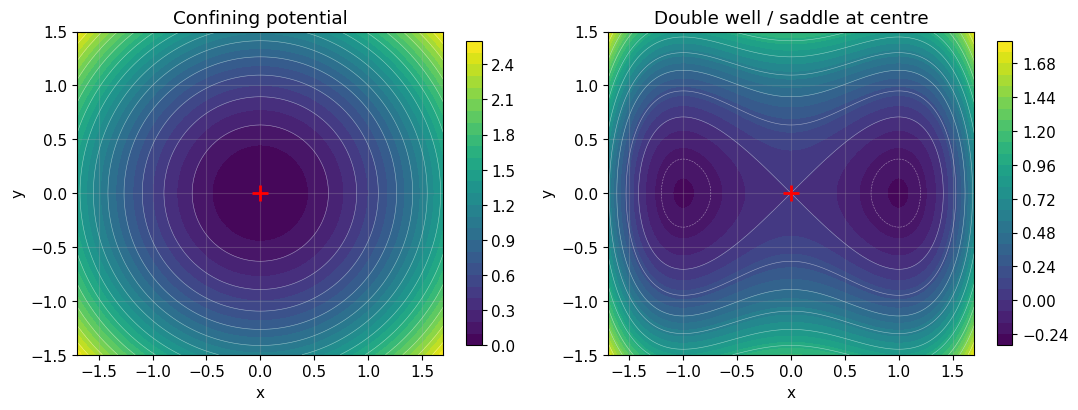

In [15]:
xx=np.linspace(-1.7,1.7,180);yy=np.linspace(-1.5,1.5,160)
X,Y=np.meshgrid(xx,yy)
Vcon=.5*(X**2+Y**2)
Vsad=.25*X**4-.5*X**2+.5*Y**2
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
for a,Z,title in zip(axs,[Vcon,Vsad],['Confining potential','Double well / saddle at centre']):
    cs=a.contourf(X,Y,Z,levels=30,cmap='viridis');a.contour(X,Y,Z,levels=12,colors='white',linewidths=.4,alpha=.5)
    a.plot(0,0,'r+',ms=11,mew=2);a.set(xlabel='x',ylabel='y',title=title,aspect='equal');fig.colorbar(cs,ax=a,shrink=.8)
fig.tight_layout();plt.show()

### Nonlinear particle: why actuator limits matter

Use the dimensionless double-well potential $V(x)=x^4/4-x^2/2$, so the force is $F(x)=x-x^3$. Without feedback, a particle displaced from the unstable centre tends towards one of the wells near $x=\pm 1$. We design a **linear LQR** using the local approximation $\ddot x\approx x-\Gamma\dot x+u$.

There is a subtle but important point: **for this particular double-well model, the ideal *unlimited* feedback $u=-k_xx-k_vv$ actually stabilises the centre globally**, not just locally, when $k_x>1$ and $\Gamma+k_v>0$. The quartic restoring term helps at large displacements. So increasing the starting displacement alone would *not* demonstrate failure of this ideal controller.

Real actuators have bounded force. To illustrate a genuine limitation, we impose a **saturation limit** $|u|\le u_{\max}$, giving

$$
u=\operatorname{clip}(-k_xx-k_vv,\,-u_{\max},\,u_{\max}).
$$

The plots below compare a small and a large initial displacement. For the larger displacement, the limited actuator cannot supply the force required to return the particle to the unstable centre, even though ideal unlimited feedback could.

This is a simplified classical illustration of feedback stabilisation and finite actuator authority; it is **not** a numerical reproduction of the paper's Fig. 5.

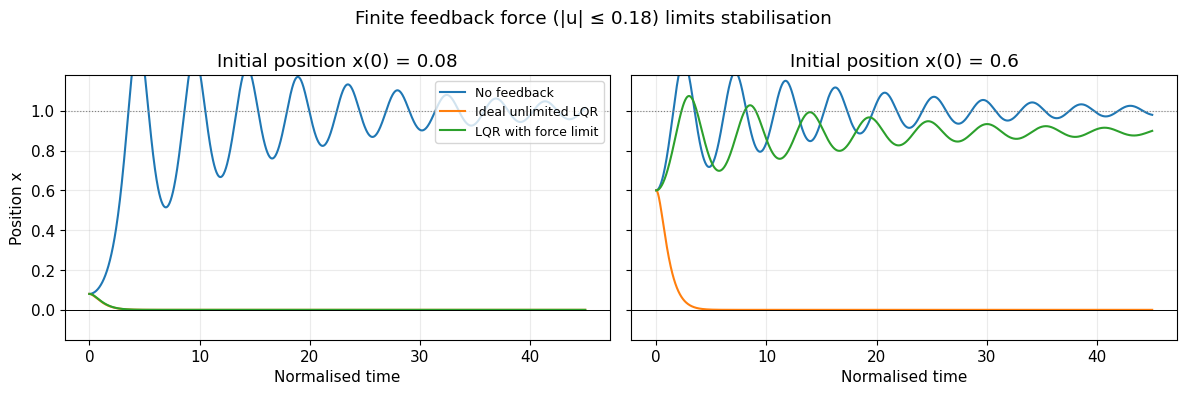

Limited feedback, x(0)=0.08: final x=0.000
Limited feedback, x(0)=0.60: final x=0.894


In [16]:
# The LQR gain K was calculated from the linearised inverted trap in section 7.
u_max = 0.18  # maximum magnitude of the normalised feedback force

def nonlinear_saddle(t, z, mode='none'):
    x, v = z
    u_ideal = -float(K.ravel() @ z)
    if mode == 'ideal':
        u = u_ideal
    elif mode == 'limited':
        u = np.clip(u_ideal, -u_max, u_max)
    else:
        u = 0.0
    return [v, x - x**3 - gamma*v + u]

# Run from a small displacement and a larger displacement, always with zero initial velocity.
tp = np.linspace(0, 45, 1300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, x_initial in zip(axes, [0.08, 0.60]):
    for mode, label in [('none', 'No feedback'),
                        ('ideal', 'Ideal unlimited LQR'),
                        ('limited', 'LQR with force limit')]:
        sol = solve_ivp(lambda t, z: nonlinear_saddle(t, z, mode),
                        [tp[0], tp[-1]], [x_initial, 0.0], t_eval=tp,
                        rtol=1e-8, atol=1e-10)
        ax.plot(sol.t, sol.y[0], label=label)
    ax.axhline(0, color='black', lw=.7)
    ax.axhline(1, color='grey', ls=':', lw=.8)
    ax.set(title=f'Initial position x(0) = {x_initial}',
           xlabel='Normalised time', ylim=(-.15, 1.18))
axes[0].set_ylabel('Position x')
axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle(f'Finite feedback force (|u| ≤ {u_max}) limits stabilisation')
fig.tight_layout()
plt.show()

# Verify the qualitative outcome numerically.
for x_initial in [0.08, 0.60]:
    sol = solve_ivp(lambda t, z: nonlinear_saddle(t, z, 'limited'),
                    [0, 100], [x_initial, 0.0], rtol=1e-8, atol=1e-10)
    print(f'Limited feedback, x(0)={x_initial:.2f}: final x={sol.y[0,-1]:.3f}')

## 11. What does the FPGA add?

The **control theory** is standard; the engineering challenge is to run it deterministically with low latency and controlled numerical error.

In the supplied paper:

- The FPGA controller uses a **64 ns sample period** (15.625 MHz) and fixed-point matrix operations.
- It supports **up to three oscillatory degrees of freedom plus a drift state**, with two analogue inputs and two outputs.
- The authors describe state-space rescaling to reduce fixed-point quantisation problems.
- A second Red Pitaya FPGA implements a stochastic nonlinear **hardware-in-the-loop (HIL) plant**, including lookup-table nonlinearities and noise generators.
- Their end-to-end example demonstrates a transition from a confining potential to a saddle potential and back, including loss of confinement when feedback is disabled.

The demonstration is **HIL, not a new measurement of quantum ground-state cooling**. In the real experiment, the simulated plant would be replaced by an optically trapped particle and the voltages would drive a physical actuator.

### Why latency matters

If feedback is delayed, a force intended to oppose velocity may arrive at the wrong phase of the oscillation. The next figure shows the phase lag $\varphi=\Omega\tau$ for several delays, as a simple first-order illustration. A full stability assessment must include the sampled controller and actuator dynamics.

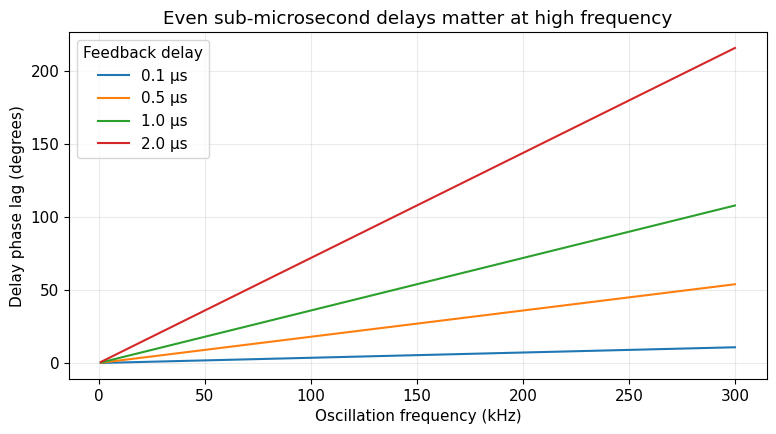

In [17]:
freq=np.linspace(1e3,300e3,400)
for delay_us in [.1,.5,1.,2.]:
    plt.plot(freq/1e3,360*freq*delay_us*1e-6,label=f'{delay_us} µs')
plt.xlabel('Oscillation frequency (kHz)');plt.ylabel('Delay phase lag (degrees)');plt.title('Even sub-microsecond delays matter at high frequency');plt.legend(title='Feedback delay');plt.show()

## 12. Putting it all together

1. **Optical field:** a focused beam creates a spatially varying optical potential.
2. **Mechanical plant:** the particle follows a noisy second-order equation of motion.
3. **Stable trap:** optical restoring forces already confine the particle; feedback can cool its motion.
4. **Saddle trap:** the desired equilibrium is unstable without feedback; active position feedback must first supply effective positive stiffness.
5. **Kalman filter:** estimates position and velocity from noisy detector outputs.
6. **LQR:** chooses feedback gains that trade state excursions against actuation effort.
7. **LQG:** combines those two components; it is an effective, not unique, route to stabilisation. Its gain selection is systematic but remains model-dependent. The FPGA makes the loop fast and deterministic.
8. **HIL:** replaces the physical particle with a nonlinear stochastic real-time simulator to test the controller safely.

### Exercises (change code and rerun)

- Increase `Rmeas` tenfold in §7. Does the Kalman estimate become less reliable? How does the LQG trajectory change?
- Increase `rcontrol` in §6. Why does the controller become less aggressive?
- Change `gamma` in §4 and re-run the simulation. What happens to the open-loop unstable pole?
- In §10, change `u_max` and the initial displacement in the nonlinear double-well example. When does **limited-force feedback** stop holding the particle near the unstable centre? Compare with unlimited feedback.
- Replace the continuous-time LQR gain in §7 with the discrete-time `Kd` computed in §8. Compare the results.
- In the controller-comparison cell after §8, change `other_poles`. How do the position response and feedback force change? What additional test would be needed to compare noise rejection fairly?

### Further reading

- Mlynář et al. (2026), *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems*, supplied PDF, especially §§2 and 4.
- Winstone et al. (2023), *Optomechanics of optically-levitated particles: A tutorial and perspective*, arXiv:2307.11858.
- Millen et al. (2020), *Optomechanics with levitated particles*, *Reports on Progress in Physics* 83, 026401.

**Limitations of this notebook:** classical linear-Gaussian noise; simplified 1D dynamics for control; illustrative normalised values; no photon-recoil quantum backaction, detailed actuator dynamics beyond a simple saturation limit, explicit fixed-point FPGA model, or detailed optical scattering calculation. These would be natural follow-on topics.